In [14]:
import pandas as pd

url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
df = pd.read_csv(url)

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [15]:
targets = ["decile_score", "is_recid"]

display(df[targets].head(10))

print("Recidivism outcome counts:")
display(df["is_recid"].value_counts(dropna=False))

print("Missing values in target columns:")
display(df[targets].isna().sum())

,decile_score,is_recid
0,1,0
1,3,1
2,4,1
3,8,0
4,1,0
5,1,0
6,6,1
7,4,0
8,1,0
9,3,1


Recidivism outcome counts:


,count
is_recid,
0,3743
1,3471


Missing values in target columns:


,0
decile_score,0
is_recid,0


In [16]:
numeric_features = [
    "age", "priors_count", "juv_fel_count",
    "juv_misd_count", "juv_other_count"
]
categorical_features = ["c_charge_degree"]
features = numeric_features + categorical_features

# Race aur sex ko baad mein fairness check ke liye rakhenge
data = df[features + targets + ["race", "sex"]].copy()

print("Missing values per column:")
display(data.isna().sum())

print("Numerical columns ka summary:")
display(data[numeric_features].describe())

Missing values per column:


,0
age,0
priors_count,0
juv_fel_count,0
juv_misd_count,0
juv_other_count,0
c_charge_degree,0
decile_score,0
is_recid,0
race,0
sex,0


Numerical columns ka summary:


,age,priors_count,juv_fel_count,juv_misd_count,juv_other_count
count,7214.000000,7214.000000,7214.000000,7214.000000,7214.000000
mean,34.817993,3.472415,0.067230,0.090934,0.109371
std,11.888922,4.882538,0.473972,0.485239,0.501586
min,18.000000,0.000000,0.000000,0.000000,0.000000
25%,25.000000,0.000000,0.000000,0.000000,0.000000
50%,31.000000,2.000000,0.000000,0.000000,0.000000
75%,42.000000,5.000000,0.000000,0.000000,0.000000
max,96.000000,38.000000,20.000000,13.000000,17.000000


In [17]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    data, test_size=0.30, random_state=92
)

print("Training rows:", len(train))
print("Testing rows:", len(test))

Training rows: 5049
Testing rows: 2165


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression

preprocess = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_features),
    ("charge", OneHotEncoder(drop="first", handle_unknown="ignore"),
     categorical_features)
])

X_train = preprocess.fit_transform(train[features])
X_test = preprocess.transform(test[features])

linear_model = LinearRegression()
linear_model.fit(X_train, train["decile_score"])

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, train["is_recid"])

print("Both models trained successfully.")

Both models trained successfully.


In [19]:
import numpy as np

linear_scores = linear_model.predict(X_test)
logistic_probs = logistic_model.predict_proba(X_test)[:, 1]

linear_cutoff = np.median(linear_scores)
linear_labels = (linear_scores >= linear_cutoff).astype(int)
logistic_labels = (logistic_probs >= 0.50).astype(int)

comparison = pd.crosstab(
    linear_labels, logistic_labels,
    rownames=["Linear prediction"],
    colnames=["Logistic prediction"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

mismatch_count = (linear_labels != logistic_labels).sum()
mismatch_percent = 100 * mismatch_count / len(test)

print(f"Linear median cutoff: {linear_cutoff:.4f}")
print("Logistic cutoff: 0.50")
display(comparison)
print(f"Mismatches: {mismatch_count} out of {len(test)}")
print(f"Mismatch percentage: {mismatch_percent:.2f}%")

Linear median cutoff: 4.6100
Logistic cutoff: 0.50


Logistic prediction,0,1
Linear prediction,,
0,1066,16
1,132,951


Mismatches: 148 out of 2165
Mismatch percentage: 6.84%


In [20]:
import statsmodels.formula.api as smf

# Same predictor, teen alag datasets
groups = {
    "Overall": data,
    "Female": data[data["sex"] == "Female"],
    "Male": data[data["sex"] == "Male"]
}

results = []

for group_name, group_data in groups.items():
    model = smf.logit(
        "is_recid ~ priors_count", data=group_data
    ).fit(disp=False)

    lower, upper = model.conf_int().loc["priors_count"]

    results.append({
        "Group": group_name,
        "Rows": len(group_data),
        "Coefficient": model.params["priors_count"],
        "95% CI lower": lower,
        "95% CI upper": upper
    })

display(pd.DataFrame(results).round(4))

# Check whether the priors_count coefficient differs by sex
interaction_model = smf.logit(
    "is_recid ~ priors_count * C(sex)", data=data
).fit(disp=False)

p_value = interaction_model.pvalues["priors_count:C(sex)[T.Male]"]
print(f"Group difference p-value: {p_value:.6g}")

,Group,Rows,Coefficient,95% CI lower,95% CI upper
0,Overall,7214,0.1436,0.1306,0.1566
1,Female,1395,0.2096,0.1681,0.2511
2,Male,5819,0.1307,0.1170,0.1444


Group difference p-value: 0.000400145


In [21]:
remaining_predictors = [
    "priors_count", "juv_fel_count",
    "juv_misd_count", "juv_other_count", "C(c_charge_degree)"
]

reduced_formula = "is_recid ~ " + " + ".join(remaining_predictors)
full_formula = reduced_formula + " + age"

full_model = smf.logit(full_formula, data=train).fit(disp=False)
reduced_model = smf.logit(reduced_formula, data=train).fit(disp=False)

changes = pd.DataFrame({
    "With age": full_model.params,
    "Without age": reduced_model.params
}).drop(index=["Intercept", "age"])

changes["Change"] = changes["Without age"] - changes["With age"]
baseline = changes["With age"].abs().replace(0, np.nan)
changes["Change (%)"] = 100 * changes["Change"] / baseline

# Biggest relative change first
order = changes["Change (%)"].abs().sort_values(ascending=False).index
display(changes.loc[order].round(4))

,With age,Without age,Change,Change (%)
juv_misd_count,-0.0359,0.1519,0.1878,522.6355
juv_other_count,0.1308,0.3381,0.2073,158.5333
juv_fel_count,0.2637,0.4415,0.1778,67.3964
C(c_charge_degree)[T.M],-0.1959,-0.2906,-0.0947,-48.3194
priors_count,0.1553,0.1236,-0.0317,-20.4358


In [22]:
test_results = test.copy()
test_results["probability"] = logistic_probs

false_positive = (
    (test_results["probability"] >= 0.75)
    & (test_results["is_recid"] == 0)
)
false_negative = (
    (test_results["probability"] <= 0.25)
    & (test_results["is_recid"] == 1)
)

confident_errors = test_results[false_positive | false_negative].copy()
confident_errors["error_type"] = np.where(
    confident_errors["is_recid"] == 0,
    "False positive",
    "False negative"
)

sample = confident_errors.sample(
    n=min(50, len(confident_errors)), random_state=92
)

print(f"Confident errors: {len(confident_errors)} out of {len(test_results)}")
print(f"Percentage of test set: {100 * len(confident_errors) / len(test_results):.2f}%")
print("False positives:", false_positive.sum())
print("False negatives:", false_negative.sum())
print("Sample size:", len(sample))

def profile(rows):
    return pd.Series({
        "Median age": rows["age"].median(),
        "Under 25 (%)": 100 * (rows["age"] < 25).mean(),
        "Age 25–45 (%)": 100 * rows["age"].between(25, 45).mean(),
        "Over 45 (%)": 100 * (rows["age"] > 45).mean(),
        "Female (%)": 100 * (rows["sex"] == "Female").mean(),
        "Male (%)": 100 * (rows["sex"] == "Male").mean(),
        "Median priors": rows["priors_count"].median(),
        "Zero priors (%)": 100 * (rows["priors_count"] == 0).mean(),
        "5+ priors (%)": 100 * (rows["priors_count"] >= 5).mean()
    })

display(pd.DataFrame({
    "Full test set": profile(test_results),
    "Error sample": profile(sample)
}).round(2))

print("Profiles by error type within the sample:")
display(pd.DataFrame({
    name: profile(rows) for name, rows in sample.groupby("error_type")
}).round(2))

print("Part 1 logistic model coefficients:")
display(pd.Series(
    logistic_model.coef_[0], index=preprocess.get_feature_names_out()
).round(4))

Confident errors: 85 out of 2165
Percentage of test set: 3.93%
False positives: 29
False negatives: 56
Sample size: 50


,Full test set,Error sample
Median age,31.00,52.0
Under 25 (%),21.48,4.0
Age 25–45 (%),57.64,20.0
Over 45 (%),20.88,76.0
Female (%),19.35,18.0
Male (%),80.65,82.0
Median priors,2.00,1.5
Zero priors (%),29.47,26.0
5+ priors (%),25.22,30.0


Profiles by error type within the sample:


,False negative,False positive
Median age,55.00,38.00
Under 25 (%),0.00,13.33
Age 25–45 (%),2.86,60.00
Over 45 (%),97.14,26.67
Female (%),25.71,0.00
Male (%),74.29,100.00
Median priors,1.00,14.00
Zero priors (%),37.14,0.00
5+ priors (%),2.86,93.33


Part 1 logistic model coefficients:


,0
numbers__age,-0.5467
numbers__priors_count,0.7642
numbers__juv_fel_count,0.1301
numbers__juv_misd_count,-0.0178
numbers__juv_other_count,0.0659
charge__c_charge_degree_M,-0.1943


,Threshold,DP,EO,PP,Accuracy,TPR Female,TPR Male,FPR Female,FPR Male
0,0.05,1.0006,1.0000,0.7391,0.4785,1.0000,1.0000,1.0000,0.9988
1,0.15,0.9845,0.9858,0.7458,0.4952,0.9872,0.9943,0.9506,0.9642
2,0.25,0.9524,0.9481,0.7362,0.5400,0.9038,0.9534,0.8213,0.8351
3,0.35,0.8945,0.9079,0.7506,0.5949,0.8077,0.8896,0.6350,0.6724
4,0.45,0.7731,0.7633,0.8519,0.6503,0.6667,0.7486,0.3460,0.4533
5,0.55,0.5055,0.3686,1.0281,0.6725,0.3590,0.5108,0.0684,0.1857
6,0.65,0.3525,0.0999,1.1598,0.6249,0.1667,0.3015,0.0076,0.0761
7,0.75,0.3277,0.1177,1.1019,0.5838,0.0833,0.1706,0.0038,0.0323
8,0.85,0.2841,0.0000,1.2055,0.5515,0.0385,0.0830,0.0000,0.0173
9,0.95,0.2604,NaN,1.0000,0.5298,0.0064,0.0182,0.0000,0.0000


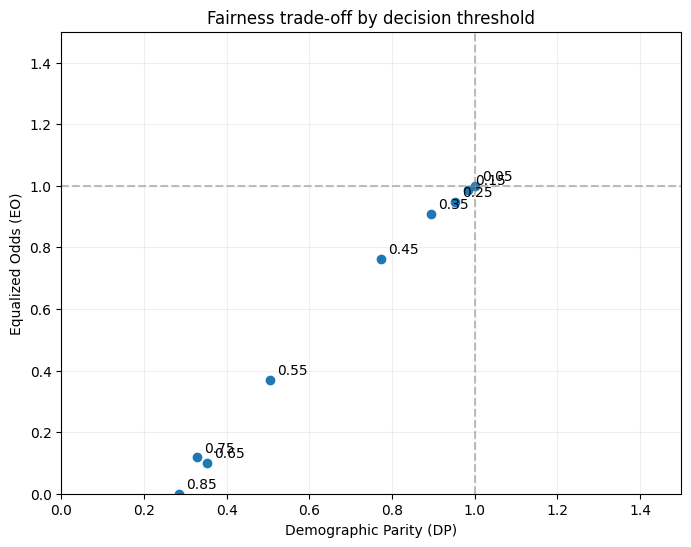

In [23]:
import matplotlib.pyplot as plt

group_a = test_results["sex"] == "Female"
group_b = test_results["sex"] == "Male"
actual = test_results["is_recid"] == 1

def ratio(a, b):
    if pd.isna(b) or b == 0:
        return np.nan
    return a / b

fairness_rows = []

for threshold in np.arange(5, 100, 10) / 100:
    flagged = test_results["probability"] >= threshold

    # TPR = actual positives mein se kitne flag hue
    tpr_a = flagged[group_a & actual].mean()
    tpr_b = flagged[group_b & actual].mean()

    # FPR = actual negatives mein se kitne flag hue
    fpr_a = flagged[group_a & ~actual].mean()
    fpr_b = flagged[group_b & ~actual].mean()

    fairness_rows.append({
        "Threshold": threshold,
        "DP": ratio(flagged[group_a].mean(), flagged[group_b].mean()),
        "EO": np.minimum(ratio(tpr_a, tpr_b), ratio(fpr_a, fpr_b)),
        "PP": ratio(actual[group_a & flagged].mean(),
                    actual[group_b & flagged].mean()),
        "Accuracy": (flagged == actual).mean(),
        "TPR Female": tpr_a,
        "TPR Male": tpr_b,
        "FPR Female": fpr_a,
        "FPR Male": fpr_b
    })

fairness = pd.DataFrame(fairness_rows)
display(fairness.round(4))

plot_points = fairness.dropna(subset=["DP", "EO"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(plot_points["DP"], plot_points["EO"])

for _, row in plot_points.iterrows():
    ax.annotate(
        f'{row["Threshold"]:.2f}', (row["DP"], row["EO"]),
        xytext=(5, 4), textcoords="offset points"
    )

ax.axvline(1, color="gray", linestyle="--", alpha=0.5)
ax.axhline(1, color="gray", linestyle="--", alpha=0.5)
ax.set(
    xlim=(0, 1.5), ylim=(0, 1.5),
    xlabel="Demographic Parity (DP)",
    ylabel="Equalized Odds (EO)",
    title="Fairness trade-off by decision threshold"
)
ax.grid(alpha=0.2)
plt.show()

In [24]:
before = fairness.loc[fairness["Threshold"] == 0.75].iloc[0]
after = fairness.loc[fairness["Threshold"] == 0.65].iloc[0]

dp_gain = 100 * (after["DP"] - before["DP"]) / before["DP"]
eo_loss = 100 * (before["EO"] - after["EO"]) / before["EO"]

print(f"DP improvement: {dp_gain:.2f}%")
print(f"EO decline: {eo_loss:.2f}%")
print(f"Trade-off cost: {eo_loss / dp_gain:.2f}")

DP improvement: 7.55%
EO decline: 15.15%
Trade-off cost: 2.01
